# Denoising Diffusion Implicit Models (DDIM)

**Paper:** Song, J., Meng, C., & Ermon, S. (2021). *Denoising Diffusion Implicit Models.* ICLR 2021. [arXiv:2010.02502](https://arxiv.org/abs/2010.02502)

This notebook implements DDIM from scratch in PyTorch:
1. **Training as in DDPM:** a noise-prediction U-Net trained with the simple MSE objective (T = 1000, β from 1e-4 to 0.02), with an EMA copy of the weights
2. **DDIM sampling:** a deterministic (η = 0), non-Markovian reverse process that uses only a subsequence of the timesteps
3. **Speed comparison:** DDIM with 50 steps against DDPM with all 1000 steps, from the same starting noise
4. **DDIM properties:** samples from the same x_T at different step counts, interpolation between two x_T, the effect of η, and encoding a real image to x_T and decoding it back

DDIM reuses the DDPM-trained model as it is; only the sampling changes. The Summary at the end says what this run found.

## 1. Setup and Imports

In [1]:
import os
# Deterministic cuBLAS kernels; must be set before torch is imported
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import atexit
import contextlib
import copy
import io
import math
import shutil
import tempfile
import time
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
# Deterministic GPU kernels where PyTorch has them (warn instead of failing for the rest)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings('ignore', message='.*deterministic.*')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## 2. Hyperparameters

T and the β schedule follow DDPM and the DDIM paper's CIFAR10 setup (T = 1000, linear β). DDIM samples with only 50 of the 1000 timesteps. The model is small and trains for 20 epochs on all 60,000 FashionMNIST images.

In [2]:
T = 1000            # diffusion steps used in training
IMG_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 128
EPOCHS = 20
LR = 2e-4
BASE_CH = 32
BETA_START = 1e-4
BETA_END = 0.02
EMA_DECAY = 0.999
DDIM_STEPS = 50     # DDIM uses 50 of the 1000 timesteps

## 3. Forward Diffusion Process

The forward process adds Gaussian noise according to a variance schedule {beta_t}.
We can sample x_t directly from x_0 in closed form:

q(x_t | x_0) = N(x_t; sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)

where alpha_bar_t = prod(1 - beta_s) for s=1..t

This is identical to DDPM — DDIM shares the same forward process.

In [3]:
def linear_beta_schedule(timesteps, beta_start, beta_end):
    return torch.linspace(beta_start, beta_end, timesteps)

betas = linear_beta_schedule(T, BETA_START, BETA_END).to(device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

def q_sample(x_0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_alpha = sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
    sqrt_one_minus = sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)
    return sqrt_alpha * x_0 + sqrt_one_minus * noise

print(f"Beta: {betas[0]:.6f} -> {betas[-1]:.6f}")
print(f"alpha_bar_0: {alphas_cumprod[0]:.6f}, alpha_bar_T: {alphas_cumprod[-1]:.6f}")

Beta: 0.000100 -> 0.020000
alpha_bar_0: 0.999900, alpha_bar_T: 0.000040


## 4. Dataset and DataLoader

In [4]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])
# Download quietly (no progress bars in the saved notebook)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    full_dataset = datasets.FashionMNIST(root=tempfile.gettempdir(), train=True, download=True,
                                         transform=transform)

# Transform all 60,000 images once and keep them as one tensor, so no DataLoader workers are needed
images = torch.stack([full_dataset[i][0] for i in range(len(full_dataset))])
dataset = TensorDataset(images)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True,
                        generator=torch.Generator().manual_seed(SEED))
print(f"Dataset size: {len(dataset)}, batches per epoch: {len(dataloader)}")

Dataset size: 60000, batches per epoch: 468


## 5. Visualize Forward Diffusion

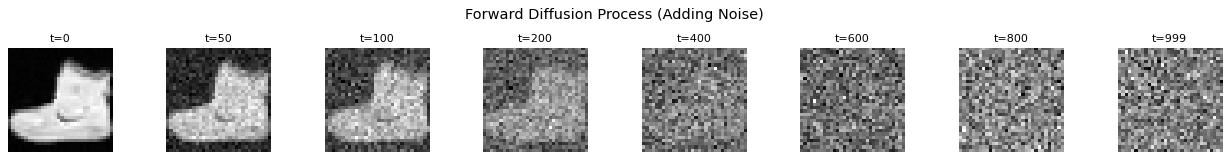

In [5]:
sample = dataset[0][0]
sample = sample.unsqueeze(0).to(device)

fig, axes = plt.subplots(1, 8, figsize=(16, 2))
timesteps_to_show = [0, 50, 100, 200, 400, 600, 800, 999]
for ax, t_val in zip(axes, timesteps_to_show):
    t_tensor = torch.tensor([t_val]).to(device)
    noisy = q_sample(sample, t_tensor)
    img = noisy.squeeze(0).squeeze(0).cpu().numpy()
    img = (img + 1) / 2
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val}', fontsize=10)
    ax.axis('off')
plt.suptitle('Forward Diffusion Process (Adding Noise)', fontsize=13)
plt.tight_layout()
plt.show()

## 6. U-Net Denoiser Architecture

The U-Net predicts the noise ε_θ(x_t, t) from x_t and the timestep t. DDIM uses the same kind of network as DDPM.
- Sinusoidal time embedding → MLP → added inside every ResBlock
- ResBlocks: GroupNorm → SiLU → Conv, twice, with a skip connection; two ResBlocks per level
- Spatial self-attention at the 16×16 resolution (each position attends to every other position)
- Resolutions 32×32 → 16×16 → 8×8 and back, with skip connections

In [6]:
def _groups(channels, max_groups=8):
    g = min(max_groups, channels)
    while channels % g != 0:
        g -= 1
    return g

class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        return embeddings

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim, max_groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(_groups(in_ch, max_groups), in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_mlp = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(_groups(out_ch, max_groups), out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        if in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1)
        else:
            self.skip = nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_mlp(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(_groups(channels), channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        self.heads = heads

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        qkv = self.qkv(h).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]
        attn = torch.einsum('bhdn,bhem->bhnm', q, k) * (C // self.heads) ** -0.5
        attn = attn.softmax(dim=-1)
        out = torch.einsum('bhnm,bhdm->bhdn', attn, v)   # weighted sum of values over the attended positions m
        out = out.reshape(B, C, H, W)
        return x + self.proj(out)

class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim, attn=False):
        super().__init__()
        self.res1 = ResBlock(in_ch, out_ch, time_dim)
        self.res2 = ResBlock(out_ch, out_ch, time_dim)
        self.attn = SelfAttention(out_ch) if attn else nn.Identity()
        self.down = nn.Conv2d(out_ch, out_ch, 3, stride=2, padding=1)

    def forward(self, x, t_emb):
        x = self.res1(x, t_emb)
        x = self.res2(x, t_emb)
        x = self.attn(x)
        return self.down(x), x  # (downsampled, skip)

class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, time_dim, attn=False):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.res1 = ResBlock(out_ch + skip_ch, out_ch, time_dim)
        self.res2 = ResBlock(out_ch, out_ch, time_dim)
        self.attn = SelfAttention(out_ch) if attn else nn.Identity()

    def forward(self, x, skip, t_emb):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        x = self.res1(x, t_emb)
        x = self.res2(x, t_emb)
        return self.attn(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, base_ch=32, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_dim),
            nn.Linear(time_dim, time_dim * 2),
            nn.SiLU(),
            nn.Linear(time_dim * 2, time_dim),
        )
        # Encoder
        self.inc = ResBlock(in_channels, base_ch, time_dim)          # 1->32,  32x32
        self.down1 = DownBlock(base_ch, base_ch * 2, time_dim)       # 32->64 at 32x32 (skip 64ch, 32x32), then down to 16x16
        self.down2 = DownBlock(base_ch * 2, base_ch * 4, time_dim, attn=True)  # 64->128 at 16x16 with attention (skip 128ch, 16x16), then down to 8x8
        # Bottleneck
        self.bot1 = ResBlock(base_ch * 4, base_ch * 4, time_dim)     # 128->128, 8x8
        self.bot2 = ResBlock(base_ch * 4, base_ch * 4, time_dim)     # 128->128, 8x8
        # Decoder
        self.up2 = UpBlock(base_ch * 4, base_ch * 4, base_ch * 2, time_dim, attn=True)  # up 8x8 -> 16x16, concat skip, attention at 16x16
        self.up1 = UpBlock(base_ch * 2, base_ch * 2, base_ch, time_dim)                  # up 16x16 -> 32x32, concat skip
        self.outc = nn.Conv2d(base_ch, in_channels, 1)               # 32->1, 32x32

    def forward(self, x, t):
        t_emb = self.time_mlp(t.float())
        x1 = self.inc(x, t_emb)           # 32ch, 32x32
        x2, s1 = self.down1(x1, t_emb)   # x2: 64ch, 16x16; s1: 64ch, 32x32
        x3, s2 = self.down2(x2, t_emb)   # x3: 128ch, 8x8; s2: 128ch, 16x16
        x3 = self.bot1(x3, t_emb)
        x3 = self.bot2(x3, t_emb)
        x = self.up2(x3, s2, t_emb)      # 64ch, 16x16
        x = self.up1(x, s1, t_emb)       # 32ch, 32x32
        return self.outc(x)

model = UNet(in_channels=CHANNELS, base_ch=BASE_CH, time_dim=128).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net parameters: {n_params:,}")

# Quick forward pass test
test_x = torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
test_t = torch.tensor([0, 500], device=device)
test_out = model(test_x, test_t)
print(f"Forward pass test: input {test_x.shape} -> output {test_out.shape}")
assert test_out.shape == test_x.shape, "Shape mismatch!"
print("Shape check passed.")

ema_model = copy.deepcopy(model).eval()
for p in ema_model.parameters():
    p.requires_grad_(False)

U-Net parameters: 2,038,243


Forward pass test: input torch.Size([2, 1, 32, 32]) -> output torch.Size([2, 1, 32, 32])
Shape check passed.


## 7. Training Loop

The simplified training objective: L = E[‖ε − ε_θ(x_t, t)‖²], the same as DDPM. DDIM's insight is that this objective only depends on the marginals q(x_t | x_0), so the same trained model can be sampled in a different, faster way (Section 4). After every step an exponential moving average (EMA) of the weights is updated; all sampling uses the EMA model.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
losses = []
start = time.time()

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for (batch,) in dataloader:
        batch = batch.to(device)
        B = batch.shape[0]
        t = torch.randint(0, T, (B,), device=device).long()
        noise = torch.randn_like(batch)
        x_t = q_sample(batch, t, noise)
        loss = F.mse_loss(model(x_t, t), noise)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            for p_ema, p in zip(ema_model.parameters(), model.parameters()):
                p_ema.mul_(EMA_DECAY).add_(p, alpha=1 - EMA_DECAY)
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(dataloader)
    losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{EPOCHS} - avg loss: {avg_loss:.4f} ({time.time() - start:.0f} s)")

print(f"Training complete: {EPOCHS * len(dataloader):,} steps")

Epoch 1/20 - avg loss: 0.0696 (101 s)


Epoch 2/20 - avg loss: 0.0364 (205 s)


Epoch 3/20 - avg loss: 0.0340 (310 s)


Epoch 4/20 - avg loss: 0.0310 (415 s)


Epoch 5/20 - avg loss: 0.0305 (519 s)


Epoch 6/20 - avg loss: 0.0293 (624 s)


... (10 outputs left out)

Epoch 17/20 - avg loss: 0.0254 (1773 s)


Epoch 18/20 - avg loss: 0.0256 (1877 s)


Epoch 19/20 - avg loss: 0.0254 (1982 s)


Epoch 20/20 - avg loss: 0.0250 (2086 s)
Training complete: 9,360 steps


## 8. Loss Curve

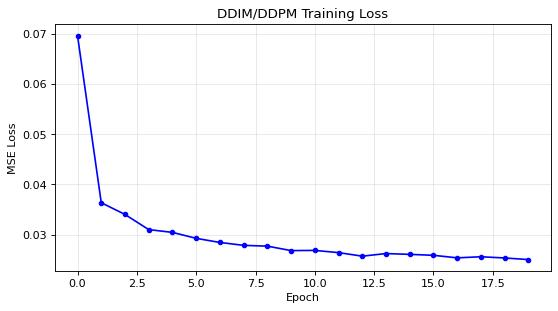

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(losses, 'b-o', markersize=4)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('DDIM/DDPM Training Loss')
plt.grid(True, alpha=0.3)
plt.show()

## 9. DDIM Sampling (The Key Innovation)

DDIM samples along a subsequence of S timesteps instead of all T (Section 4.2). With η = 0 the process is deterministic.

**Algorithm:**
1. Pick S evenly spaced timesteps τ = [0, T/S, 2T/S, ...] (here 0, 20, ..., 980 for S = 50)
2. Start from x_T ~ N(0, I)
3. For each step, from the last τ down to the first:
   - Predict the noise: ε = ε_θ(x_t, t)
   - Predict x_0: x0_pred = (x_t − √(1 − ᾱ_t) · ε) / √ᾱ_t
   - Direction pointing to x_t: dir = √(1 − ᾱ_prev − σ²) · ε
   - Update: x_prev = √ᾱ_prev · x0_pred + dir + σ · z
   - σ = η · √((1 − ᾱ_prev)/(1 − ᾱ_t)) · √(1 − ᾱ_t/ᾱ_prev); η = 0 gives DDIM, η = 1 gives a DDPM-like stochastic process (Eq. 12 and 16 of the paper)

In [9]:
@torch.no_grad()
def ddim_sample(model, x_T, ddim_steps=20, eta=0.0):
    """
    DDIM deterministic sampling.
    eta=0: pure DDIM (deterministic)
    eta=1: equivalent to DDPM
    """
    model.eval()
    B = x_T.shape[0]
    
    # Select evenly-spaced timestep subsequence
    step_ratio = T // ddim_steps
    timesteps = list(range(0, T, step_ratio))  # e.g. [0, 20, ..., 980] for 50 steps
    timesteps = list(reversed(timesteps))
    
    x_t = x_T.clone()
    
    for i, t_cur in enumerate(timesteps):
        t_tensor = torch.full((B,), t_cur, device=device, dtype=torch.long)
        eps_theta = model(x_t, t_tensor)
        
        alpha_bar_t = alphas_cumprod[t_cur]
        
        # Predict x_0
        x0_pred = (x_t - sqrt_one_minus_alphas_cumprod[t_cur] * eps_theta) / sqrt_alphas_cumprod[t_cur]
        
        if i < len(timesteps) - 1:
            t_prev = timesteps[i + 1]
        else:
            t_prev = -1  # done
        
        if t_prev >= 0:
            alpha_bar_prev = alphas_cumprod[t_prev]
        else:
            alpha_bar_prev = torch.tensor(1.0, device=device)
        
        # DDIM sigma for stochastic version
        if eta > 0 and t_prev >= 0:
            sigma = eta * torch.sqrt((1 - alpha_bar_prev) / (1 - alpha_bar_t) * (1 - alpha_bar_t / alpha_bar_prev))
        else:
            sigma = 0.0
        
        # Direction pointing to x_t
        dir_xt = torch.sqrt(1 - alpha_bar_prev - sigma ** 2) * eps_theta
        
        # DDIM update
        if eta > 0 and t_prev >= 0:
            noise = torch.randn_like(x_t)
        else:
            noise = 0.0
        x_t = torch.sqrt(alpha_bar_prev) * x0_pred + dir_xt + sigma * noise
    
    return x_t



@torch.no_grad()
def ddim_invert(model, x_0, ddim_steps=50):
    """Run the deterministic (eta = 0) DDIM update forward, x_0 -> x_T, on the same timesteps the sampler uses.
    This is the encoding of Section 5.4; ddim_sample then decodes x_T back to x_0."""
    model.eval()
    B = x_0.shape[0]
    step_ratio = T // ddim_steps
    timesteps = list(range(0, T, step_ratio))  # e.g. [0, 20, ..., 980]
    x_t = x_0.clone()
    for t_cur, t_next in zip(timesteps[:-1], timesteps[1:]):
        eps_theta = model(x_t, torch.full((B,), t_cur, device=device, dtype=torch.long))
        x0_pred = (x_t - sqrt_one_minus_alphas_cumprod[t_cur] * eps_theta) / sqrt_alphas_cumprod[t_cur]
        x_t = sqrt_alphas_cumprod[t_next] * x0_pred + sqrt_one_minus_alphas_cumprod[t_next] * eps_theta
    return x_t

print("DDIM sampler and encoder defined.")

DDIM sampler and encoder defined.


## 10. DDPM Sampling (Baseline for Comparison)

Standard stochastic DDPM sampling through all T = 1000 steps, with the posterior variance β̃_t.

In [10]:
@torch.no_grad()
def p_sample(model, x_t, t_index):
    t = torch.full((x_t.shape[0],), t_index, device=device, dtype=torch.long)
    eps_theta = model(x_t, t)

    beta_t = betas[t_index]
    sqrt_recip_alpha_t = sqrt_recip_alphas[t_index]
    sqrt_one_minus_alpha_t = sqrt_one_minus_alphas_cumprod[t_index]

    mean = sqrt_recip_alpha_t * (x_t - beta_t / sqrt_one_minus_alpha_t * eps_theta)

    if t_index > 0:
        posterior_var = posterior_variance[t_index]
        noise = torch.randn_like(x_t)
        return mean + torch.sqrt(posterior_var) * noise
    else:
        return mean

@torch.no_grad()
def p_sample_loop(model, x_T):
    model.eval()
    x_t = x_T.clone()
    for i in reversed(range(T)):
        x_t = p_sample(model, x_t, i)
    return x_t

print("DDPM sampler defined.")

DDPM sampler defined.


## 11. Speed Comparison: DDIM vs DDPM

Generate 64 samples with each method from the same initial noise, using the EMA model, and compare wall-clock time.

In [11]:
N_SAMPLES = 64
torch.manual_seed(SEED)
x_T = torch.randn(N_SAMPLES, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)

def timed(fn):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    out = fn()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return out, time.time() - t0

ddim_samples, ddim_time = timed(lambda: ddim_sample(ema_model, x_T, ddim_steps=DDIM_STEPS, eta=0.0))
print(f"DDIM: {DDIM_STEPS} steps, {ddim_time:.2f} s")
ddpm_samples, ddpm_time = timed(lambda: p_sample_loop(ema_model, x_T))
print(f"DDPM: {T} steps, {ddpm_time:.2f} s")
print(f"Speed-up: {ddpm_time / ddim_time:.1f}x faster with DDIM")

real = images[:N_SAMPLES].to(device)
for name, s in [('DDIM', ddim_samples), ('DDPM', ddpm_samples), ('Real', real)]:
    print(f"{name:<5} pixel mean {s.mean().item():.3f}, std {s.std().item():.3f}, "
          f"share of near-black pixels (< -0.9) {(s < -0.9).float().mean().item():.3f}")

DDIM: 50 steps, 1.54 s


DDPM: 1000 steps, 31.13 s
Speed-up: 20.2x faster with DDIM
DDIM  pixel mean -0.488, std 0.631, share of near-black pixels (< -0.9) 0.513
DDPM  pixel mean -0.485, std 0.640, share of near-black pixels (< -0.9) 0.525
Real  pixel mean -0.425, std 0.683, share of near-black pixels (< -0.9) 0.504


## 12. Visualize DDIM vs DDPM Samples

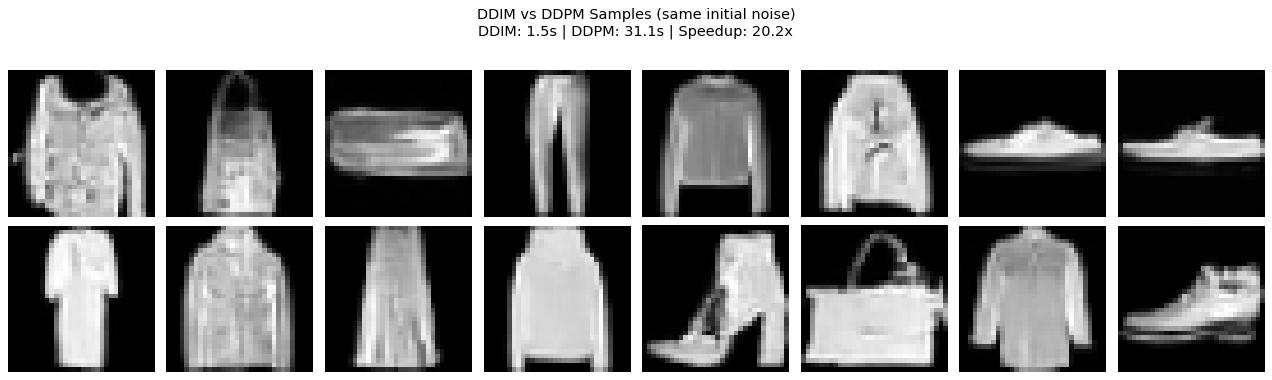

In [12]:
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

# DDIM samples
ddim_display = ((ddim_samples + 1) / 2).clamp(0, 1)
for i in range(8):
    img = ddim_display[i].squeeze(0).cpu().numpy()
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].axis('off')
axes[0, 0].set_ylabel(f'DDIM\n({DDIM_STEPS} steps)', fontsize=11)

# DDPM samples
ddpm_display = ((ddpm_samples + 1) / 2).clamp(0, 1)
for i in range(8):
    img = ddpm_display[i].squeeze(0).cpu().numpy()
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].axis('off')
axes[1, 0].set_ylabel(f'DDPM\n({T} steps)', fontsize=11)

plt.suptitle(f'DDIM vs DDPM Samples (same initial noise)\nDDIM: {ddim_time:.1f}s | DDPM: {ddpm_time:.1f}s | Speedup: {ddpm_time/ddim_time:.1f}x', fontsize=13)
plt.tight_layout()
plt.show()

## 13. DDIM Consistency: Different Step Counts

The paper notes that, with η = 0, samples from the same x_T at different step counts share high-level features (Section 5.2). Here we decode the same x_T with 10 to 1000 steps and measure how far each is from the 1000-step result.

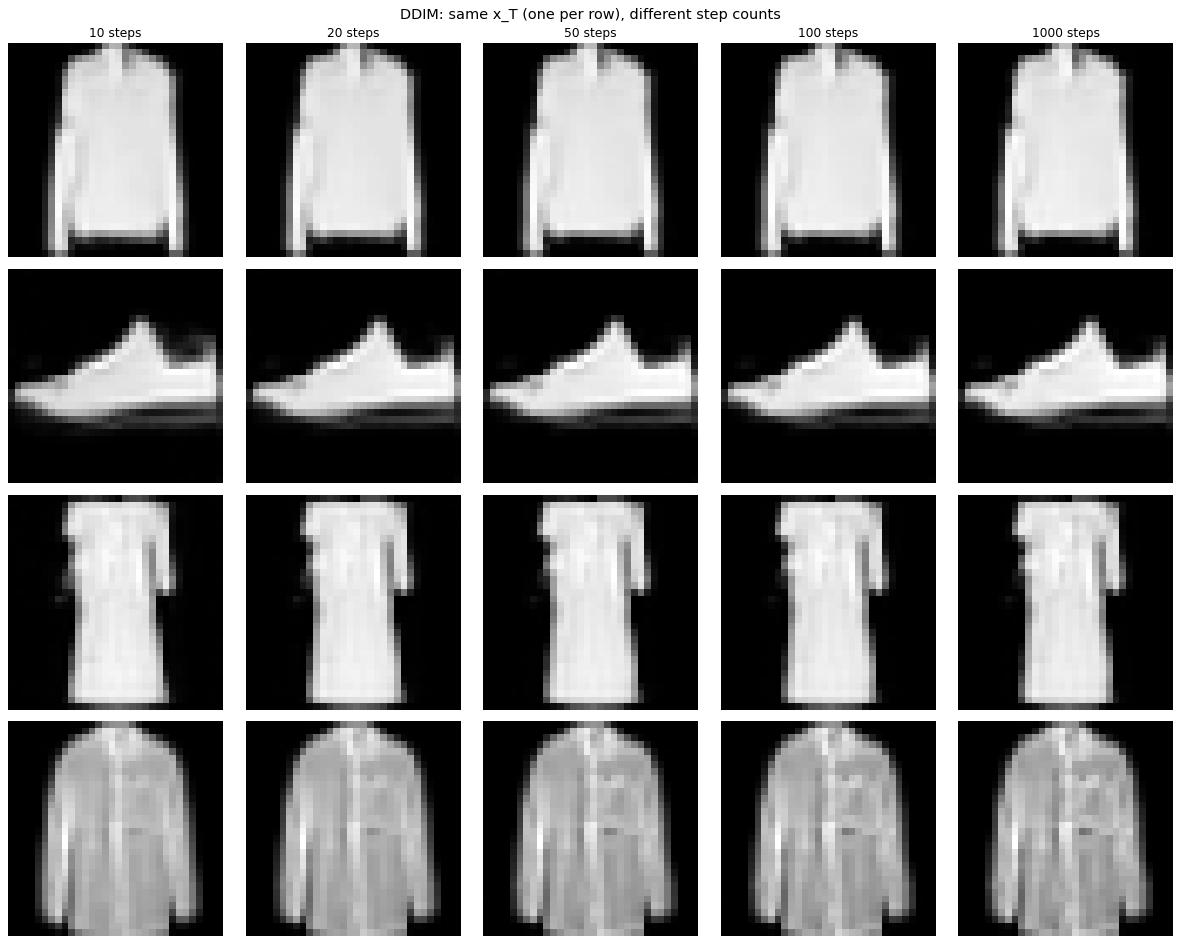

MSE (pixels in [0, 1]) to the 1000-step sample from the same x_T,   10 steps: 0.0015
MSE (pixels in [0, 1]) to the 1000-step sample from the same x_T,   20 steps: 0.0004
MSE (pixels in [0, 1]) to the 1000-step sample from the same x_T,   50 steps: 0.0001
MSE (pixels in [0, 1]) to the 1000-step sample from the same x_T,  100 steps: 0.0000
For scale, MSE (pixels in [0, 1]) between 1000-step samples from different x_T: 0.1085


In [13]:
torch.manual_seed(SEED + 1)
single_x_T = torch.randn(4, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
step_counts = [10, 20, 50, 100, 1000]
results = {s: ddim_sample(ema_model, single_x_T, ddim_steps=s, eta=0.0) for s in step_counts}

fig, axes = plt.subplots(4, len(step_counts), figsize=(3 * len(step_counts), 12))
for j, steps in enumerate(step_counts):
    for i in range(4):
        axes[i, j].imshow(((results[steps][i, 0] + 1) / 2).clamp(0, 1).cpu().numpy(), cmap='gray')
        axes[i, j].axis('off')
    axes[0, j].set_title(f'{steps} steps', fontsize=11)
plt.suptitle('DDIM: same x_T (one per row), different step counts', fontsize=13)
plt.tight_layout()
plt.show()

ref = results[1000]
other = ddim_sample(ema_model, torch.randn_like(single_x_T), ddim_steps=1000, eta=0.0)
for steps in step_counts[:-1]:
    print(f"MSE (pixels in [0, 1]) to the 1000-step sample from the same x_T, {steps:>4} steps: {F.mse_loss((results[steps] + 1) / 2, (ref + 1) / 2).item():.4f}")
print(f"For scale, MSE (pixels in [0, 1]) between 1000-step samples from different x_T: {F.mse_loss((other + 1) / 2, (ref + 1) / 2).item():.4f}")

## 14. Latent Space Interpolation

Because DDIM with η = 0 is deterministic, x_T acts as a latent code. Following the paper (Section 5.3), we interpolate spherically between two x_T and decode each point.

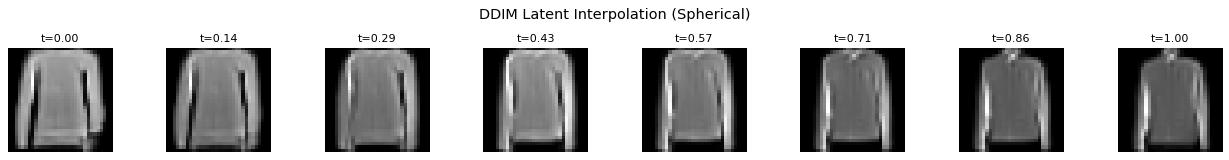

In [14]:
def slerp(t, v0, v1):
    """Spherical linear interpolation between two tensors."""
    v0_flat = v0.flatten()
    v1_flat = v1.flatten()
    v0_norm = v0_flat / (torch.norm(v0_flat) + 1e-8)
    v1_norm = v1_flat / (torch.norm(v1_flat) + 1e-8)
    dot = torch.clamp(torch.dot(v0_norm, v1_norm), -1.0, 1.0)
    omega = torch.acos(dot)
    if omega.abs() < 1e-5:
        result = (1 - t) * v0 + t * v1
    else:
        so = torch.sin(omega)
        result = torch.sin((1 - t) * omega) / so * v0 + torch.sin(t * omega) / so * v1
    return result

# Two random latent codes
torch.manual_seed(SEED + 2)
x_T_a = torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
x_T_b = torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)

n_interp = 8
fig, axes = plt.subplots(1, n_interp, figsize=(16, 2))

for i, ax in enumerate(axes):
    t_val = i / (n_interp - 1)
    x_T_interp = slerp(t_val, x_T_a, x_T_b)
    sample_img = ddim_sample(ema_model, x_T_interp, ddim_steps=DDIM_STEPS, eta=0.0)
    img = ((sample_img + 1) / 2).clamp(0, 1).squeeze(0).squeeze(0).cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val:.2f}', fontsize=10)
    ax.axis('off')

plt.suptitle('DDIM Latent Interpolation (Spherical)', fontsize=13)
plt.tight_layout()
plt.show()

## 15. Effect of eta Parameter

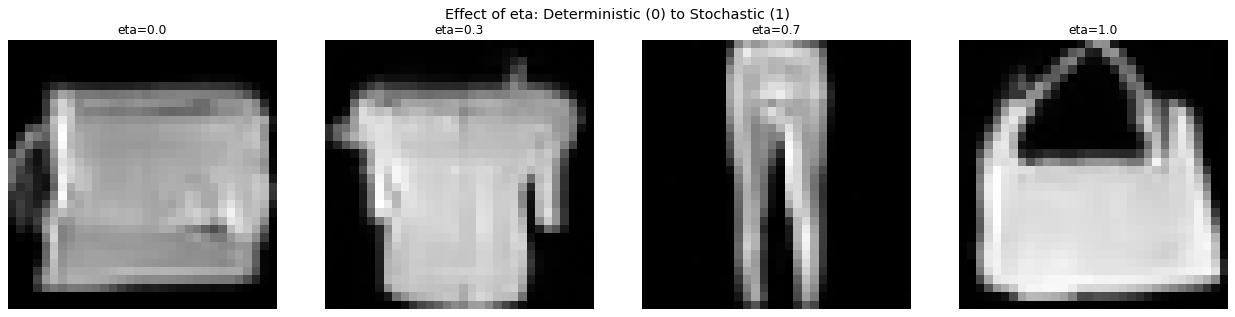

In [15]:
# Same x_T, different eta values (0=deterministic, 1=DDPM-like)
torch.manual_seed(SEED + 3)
interp_x_T = torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
eta_values = [0.0, 0.3, 0.7, 1.0]

for ax, eta_val in zip(axes, eta_values):
    sample_img = ddim_sample(ema_model, interp_x_T, ddim_steps=DDIM_STEPS, eta=eta_val)
    img = ((sample_img + 1) / 2).clamp(0, 1).squeeze(0).squeeze(0).cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.set_title(f'eta={eta_val}', fontsize=11)
    ax.axis('off')

plt.suptitle('Effect of eta: Deterministic (0) to Stochastic (1)', fontsize=13)
plt.tight_layout()
plt.show()

## 16. Reconstruction Test

Because the η = 0 process is deterministic, it can also be run forward: encode a real image x_0 into x_T with the DDIM process, then decode it back (Section 5.4). We do this for 8 real images with 50 and with 200 steps and measure the reconstruction error.

 50 steps: x_T std 0.689, reconstruction MSE (pixels scaled to [0, 1], as in the paper's Table 2) 0.0037


200 steps: x_T std 0.773, reconstruction MSE (pixels scaled to [0, 1], as in the paper's Table 2) 0.0003


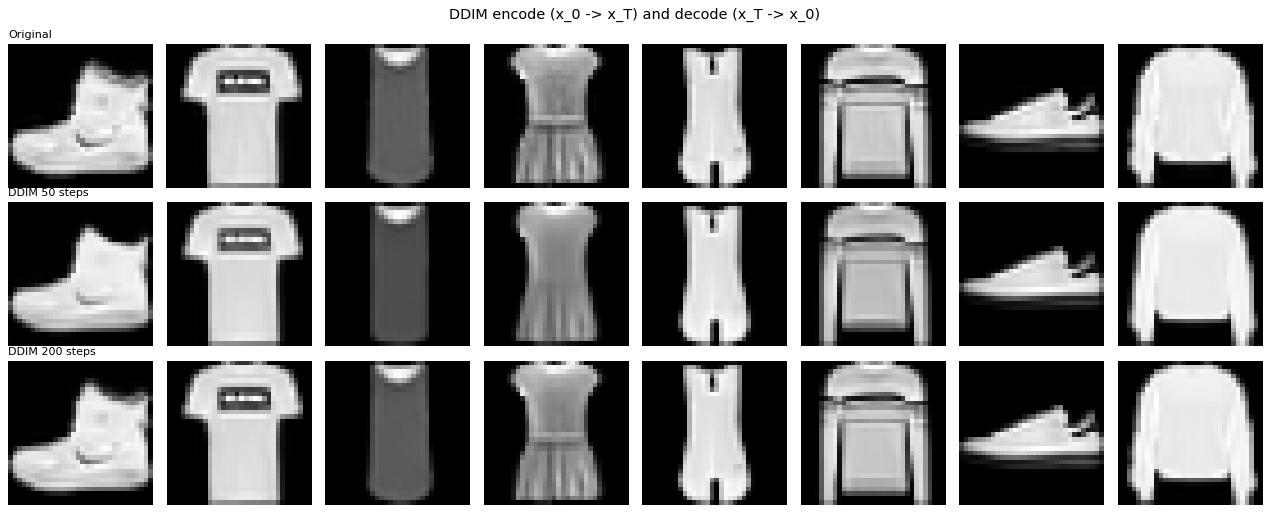

In [16]:
real_imgs = images[:8].to(device)
recon = {}
for steps in [50, 200]:
    x_T_enc = ddim_invert(ema_model, real_imgs, ddim_steps=steps)
    recon[steps] = ddim_sample(ema_model, x_T_enc, ddim_steps=steps, eta=0.0)
    print(f"{steps:>3} steps: x_T std {x_T_enc.std().item():.3f}, reconstruction MSE (pixels scaled to [0, 1], as in the paper's Table 2) {F.mse_loss((recon[steps] + 1) / 2, (real_imgs + 1) / 2).item():.4f}")

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    for row, (img, label) in enumerate([(real_imgs, 'Original'), (recon[50], 'DDIM 50 steps'), (recon[200], 'DDIM 200 steps')]):
        axes[row, i].imshow(((img[i, 0] + 1) / 2).clamp(0, 1).cpu().numpy(), cmap='gray')
        axes[row, i].axis('off')
        if i == 0:
            axes[row, i].set_title(label, fontsize=10, loc='left')
plt.suptitle('DDIM encode (x_0 -> x_T) and decode (x_T -> x_0)', fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
print("=" * 60)
print("DDIM vs DDPM Summary")
print("=" * 60)
print(f"Training: DDPM objective, {EPOCHS} epochs on {len(dataset):,} images, T = {T}, final loss {losses[-1]:.4f}")
print(f"DDIM sampling: {DDIM_STEPS} steps, {ddim_time:.2f}s")
print(f"DDPM sampling: {T} steps, {ddpm_time:.2f}s")
print(f"Speed-up: {ddpm_time / ddim_time:.1f}x")
print(f"U-Net parameters: {n_params:,}")
print("=" * 60)
print("=" * 60)

DDIM vs DDPM Summary
Training: DDPM objective, 20 epochs on 60,000 images, T = 1000, final loss 0.0250
DDIM sampling: 50 steps, 1.54s
DDPM sampling: 1000 steps, 31.13s
Speed-up: 20.2x
U-Net parameters: 2,038,243


## 17. Summary

### What the run above shows

- **Training:** the 2,038,243-parameter U-Net trained for 20 epochs (9,360 steps) on all 60,000 FashionMNIST images with T = 1000. The average loss fell from 0.0696 in the first epoch to 0.0250 in the last.
- **Speed:** from the same 64 starting noises, DDIM with 50 steps took 1.54 s and DDPM with all 1000 steps took 31.13 s on the GPU, a measured speed-up of 20.2×, close to the 20× fewer steps.
- **Samples:** both samplers produce recognisable clothing (tops, trousers, dresses, sneakers, boots, bags), with soft details. Their pixel statistics are close to 64 real images (mean −0.488 for DDIM, −0.485 for DDPM, −0.425 real). We did not measure FID, so this does not show which sampler is better.
- **Consistency:** decoding the same x_T with 10, 20, 50 or 100 DDIM steps gives the same item as with 1000 steps; the mean squared difference (pixels in [0, 1]) to the 1000-step image was 0.0015, 0.0004, 0.0001 and below 0.0001, against 0.1085 between 1000-step images from different x_T. This matches the paper's consistency property (Section 5.2).
- **Interpolation:** moving spherically between two x_T gives a smooth change between two different tops.
- **η:** for one x_T, η = 0, 0.3, 0.7 and 1.0 gave four different items, because with η > 0 each step adds fresh noise.
- **Encoding:** encoding 8 real images to x_T with the deterministic DDIM process and decoding them back gave a reconstruction error of 0.0037 with 50 steps and 0.0003 with 200 steps (pixels in [0, 1]); the paper's Table 2 reports 0.0023 and 0.0004 on CIFAR-10. The encoded x_T had a standard deviation of 0.69–0.77, not exactly the 1.0 of the Gaussian noise used for sampling.

This is a small model on 32×32 grayscale images. An earlier version of this notebook trained for 3 epochs on 5,000 images with T = 100 and a self-attention layer that did nothing, and its samples were noise; its "reconstruction" only added noise and denoised it, instead of encoding with DDIM.
